# **Problem Statement**

COVID-19 is a highly infectious disease that affects the human respiratory system, especially the lungs. Detecting COVID-19 from medical images can be challenging and time-consuming when performed manually.

## **Business Context**

*COVID-19* screening can benefit from tools that help analyze medical images consistently. This notebook explores whether a convolutional neural network (CNN) can distinguish COVID-labeled images from Normal-labeled images. The model is an educational experiment, not a substitute for professional medical diagnosis.



## **Objective**

The objective is to prepare the labeled image data, train and compare two CNN architectures, and evaluate their ability to classify images as *COVID or Normal.* Performance is assessed using accuracy and COVID-class recall.

## **Data Description**

The dataset contains 251 color images, each with a resolution of 128 × 128 pixels and three color channels. Each image has a corresponding label: Covid or Normal. There are 111 Covid images and 140 Normal images.



# **IMPORTING THE NECESSARY LIBRARIES**

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



from tensorflow.keras.models import Sequential
from tensorflow import keras
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout , Input
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
import time

# **LOADING THE IMAGES,LABEL DATASETS**


The image array has been loaded from the .npy file. Each item in the array represents one image that will be paired with its label for analysis and model training.

In [ ]:
images = np.load("C:/Users/acer/Downloads/CovidImages  (1).npy")

The labels have been loaded from the CSV file. Each row corresponds to an image, so the image and label counts should match before further processing.

In [ ]:
images = np.load("C:/Users/acer/Downloads/CovidLabels (1) (1).csv")

# **DATA OVERVIEW**

Before checking the data shapes
The following checks confirm the dimensions of the image array and label table, and help verify that the data is in the expected format.

In [4]:
print(images.shape)


(251, 128, 128, 3)


The image array has shape (251, 128, 128, 3): it contains 251 images, each 128 pixels high, 128 pixels wide, and represented with three color channels.

In [5]:
print(labels.shape)

(251, 1)


The label table has shape (251, 1), meaning it contains one label for each of the 251 images. This matches the number of images.

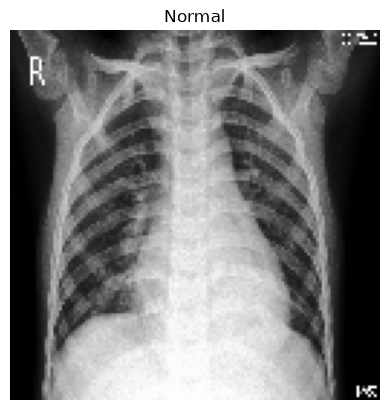

In [6]:
plt.imshow(images[5])
plt.title(labels.iloc[5, 0])
plt.axis('off')
plt.show()

# **EXPLORATORY DATA ANALYSIS**

The image grid provides a visual sample of images from across the dataset. Comparing images with their labels gives a basic sense of the data, though visual inspection alone canno

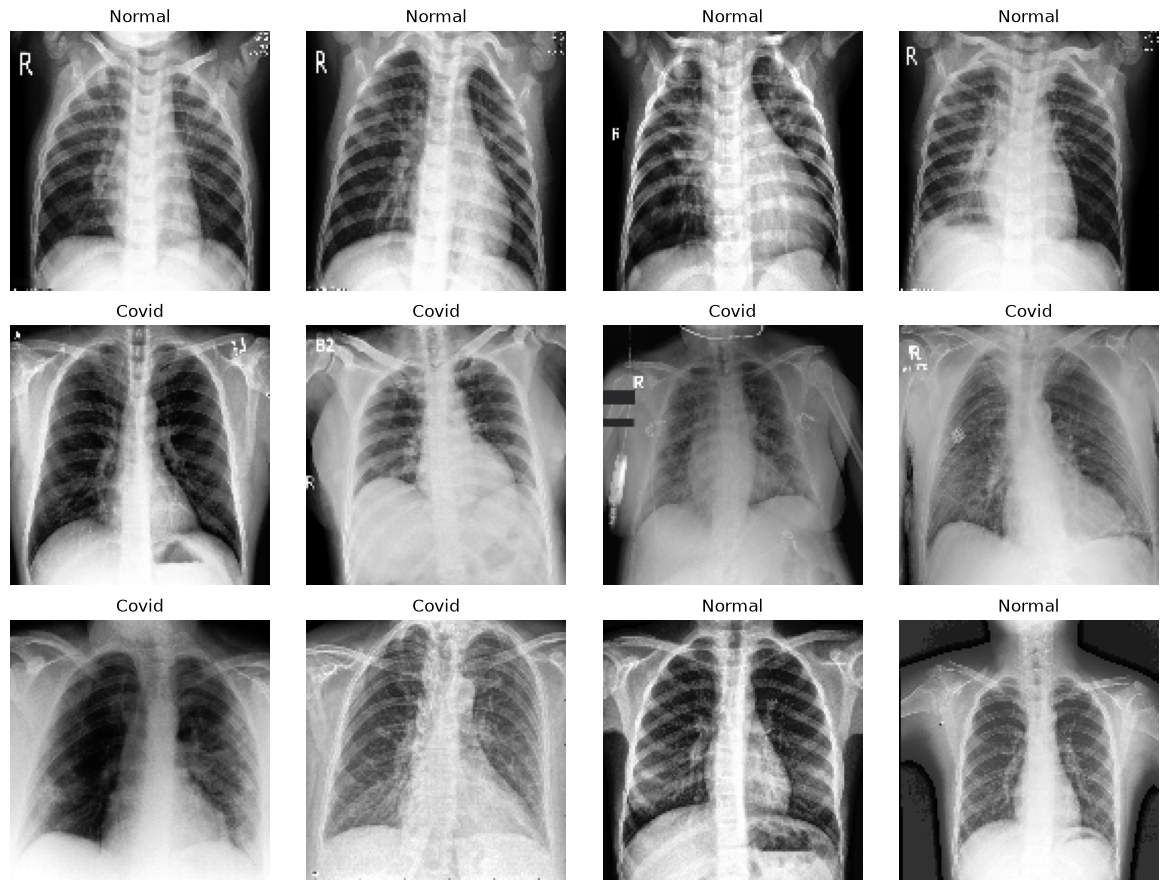

In [7]:

plt.figure(figsize=(12, 9))
for i in range(12):
  plt.subplot(3,4, i+1)
  plt.imshow(images[i*20])
  plt.title(labels.iloc[i*20, 0])
  plt.axis('off')
plt.tight_layout()
plt.show()

The chart shows how many images belong to each class. The dataset contains more Normal images than Covid images, so the classes are not perfectly balanced.

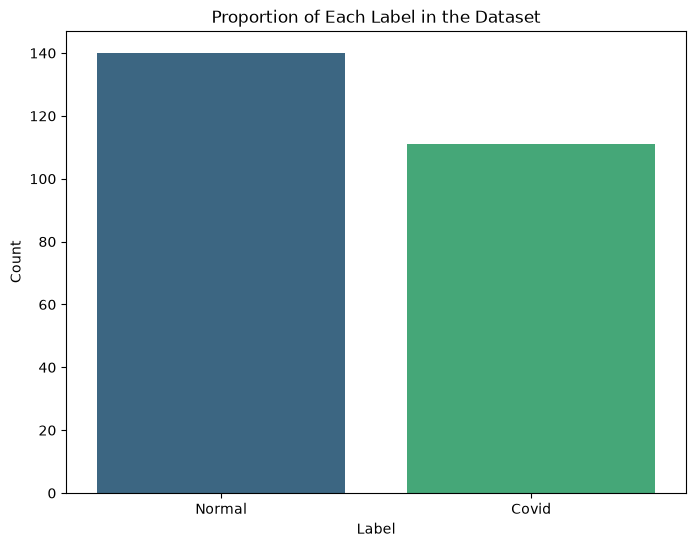

In [8]:

plt.figure(figsize=(8, 6))
sns.countplot(x='Label', data=labels, hue='Label', palette='viridis')
plt.title('Proportion of Each Label in the Dataset')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

# **DATA PREPROCESSING**

The labels are converted into numeric values so they can be used by the model: Covid is encoded as 1, and Normal as 0.

In [9]:
labels['Label'] = labels['Label'].map({'Covid': 1, 'Normal': 0})


The data is split into training, validation, and test sets. Stratification helps preserve the class proportions across the splits, while the fixed random state makes the split reproducible.

In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(images, labels['Label'], test_size=0.3, random_state=42, stratify=labels['Label'])

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Training set shape: {X_train.shape}, {y_train.shape}")
print(f"Validation set shape: {X_val.shape}, {y_val.shape}")
print(f"Test set shape: {X_test.shape}, {y_test.shape}")

Training set shape: (175, 128, 128, 3), (175,)
Validation set shape: (38, 128, 128, 3), (38,)
Test set shape: (38, 128, 128, 3), (38,)


the split contains 175 training images, 38 validation images, and 38 test images. The training set is used to fit the models, the validation set to assess performance during development, and the test set for a final evaluation.

# **DATA NORMALIZATION**

Image pixel values originally range from 0 to 255. Scaling them to the 0–1 range makes the input values smaller and more consistent for neural-network training.

we do scaling for the way too large range (255) to 0 to 1 

In [11]:

X_train_normalized = X_train / 255.0
X_val_normalized = X_val / 255.0
X_test_normalized = X_test / 255.0

print(f"Normalized training set min/max: {X_train_normalized.min()}/{X_train_normalized.max()}")
print(f"Normalized validation set min/max: {X_val_normalized.min()}/{X_val_normalized.max()}")
print(f"Normalized test set min/max: {X_test_normalized.min()}/{X_test_normalized.max()}")

Normalized training set min/max: 0.0/1.0
Normalized validation set min/max: 0.0/1.0
Normalized test set min/max: 0.0/1.0


The minimum and maximum checks confirm that the image values in the training, validation, and test sets are now between 0 and 1.

In [12]:
evaluation_results = pd.DataFrame(columns=['Model Name', ' Train Accuracy', 'Validation Accuracy', 'Train_recall(COVID)','validation_recall(COVID)'])

An empty results table is created to collect and compare the training and validation metrics for each CNN model.

# **Model 1-CNN**

The current Keras session is cleared before building the first model. This helps release resources and avoids carrying model state over from earlier work.

In [13]:
import gc
tf.keras.backend.clear_session()
gc.collect()

2626

The first CNN uses three convolutional layers with increasing numbers of filters, followed by pooling layers that reduce the spatial dimensions. Dense layers use the extracted image features to produce a binary prediction.

In [14]:
model_cnn1= Sequential([
    Input(shape=(128, 128, 3)),
    Conv2D(32, (3, 3), activation='relu',padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu',padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu',padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

The model is compiled with the Adam optimizer and binary cross-entropy loss, which are suitable choices for this binary classification task. Accuracy is tracked during evaluation.

In [15]:
optimizer = tf.keras.optimizers.Adam()
model_cnn1.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

The model summary lists the layers, output shapes, and parameter counts. It can be used to verify the model’s structure before training.

In [16]:
model_cnn1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

The first CNN is trained for 10 epochs using batches of 8 images. Training accuracy and loss show how the model fits the training data; they do not, by themselves, measure performance on unseen images.

In [17]:
start_time = time.time()
history = model_cnn1.fit(X_train_normalized, y_train, epochs=10, batch_size=8)
end_time = time.time()

training_time = end_time - start_time
print(f"Training time: {training_time:.2f} seconds")

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - accuracy: 0.6914 - loss: 0.6206
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9486 - loss: 0.1919
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9657 - loss: 0.0753
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.9829 - loss: 0.0582
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 1.0000 - loss: 0.0114
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 1.0000 - loss: 0.0108
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - accuracy: 0.8629 - loss: 0.5422
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9600 - loss: 0.0965
Epoch 9/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.9771 - loss: 0.0655
Epoch 10/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - accuracy: 0.9657 - loss: 0.0756
Training time: 27.83 seconds


In [18]:
train_loss, train_acc = model_cnn1.evaluate(X_train_normalized, y_train, verbose=0)

val_loss, val_acc = model_cnn1.evaluate(X_val_normalized, y_val, verbose=0)

y_train_pred_prob = model_cnn1.predict(X_train_normalized)
y_val_pred_prob = model_cnn1.predict(X_val_normalized)

y_train_pred = (y_train_pred_prob > 0.5).astype(int)
y_val_pred = (y_val_pred_prob > 0.5).astype(int)

train_classification_report = classification_report(y_train, y_train_pred,output_dict=True)
val_classification_report = classification_report(y_val, y_val_pred,output_dict=True)

train_recall_covid = train_classification_report['1']['recall']
val_recall_covid = val_classification_report['1']['recall']

new_row = pd.DataFrame([{
    'Model Name': 'CNN Model 1(3 Conv Layers)',
    'Train Accuracy': train_acc,
    'Validation Accuracy': val_acc,
    'Train Recall (Covid)': train_recall_covid,
    'Validation Recall (Covid)': val_recall_covid,
}])
evaluation_results=pd.concat([evaluation_results,new_row], ignore_index=True)

print(evaluation_results)
evaluation_results




6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step 
                   Model Name  Train Accuracy Validation Accuracy  \
0  CNN Model 1(3 Conv Layers)             NaN                 1.0   

  Train_recall(COVID) validation_recall(COVID)  Train Accuracy  \
0                 NaN                      NaN        0.982857   

   Train Recall (Covid)  Validation Recall (Covid)  
0              0.961039                        1.0  


,Model Name,Train Accuracy,Validation Accuracy,Train_recall(COVID),validation_recall(COVID),Train Accuracy,Train Recall (Covid),Validation Recall (Covid)
0,CNN Model 1(3 Conv Layers),NaN,1.0,NaN,NaN,0.982857,0.961039,1.0


The first CNN is trained for 10 epochs using batches of 8 images. Training accuracy and loss show how the model fits the training data; they do not, by themselves, measure performance on unseen images.

# **Model-2**

The Keras session is cleared again so the second model can be created independently of the first.

In [19]:
import gc
tf.keras.backend.clear_session()
gc.collect()

0

The second CNN uses two convolutional layers followed by dense layers. Its architecture differs from the first model, allowing a comparison of their results on the same data splits.

In [20]:
model_cnn2= Sequential([
    Input(shape=(X_train_normalized.shape[1],X_train_normalized.shape[2],X_train_normalized.shape[3])),
    Conv2D(32, (3, 3), activation='relu',padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu',padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

The second model uses the Adam optimizer, binary cross-entropy loss, and accuracy as its tracked metric, consistent with the first model.

In [21]:
optimizer = tf.keras.optimizers.Adam()
model_cnn2.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

The summary shows the second model’s layer structure and parameter counts. Comparing it with the first model helps illustrate the differences between the architectures.

In [22]:
model_cnn2.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     8,388,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,416,449 (32.11 MB)

 Trainable params: 8,416,449 (32.11 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
start_time = time.time()
history = model_cnn2.fit(X_train_normalized, y_train, epochs=10, batch_size=8)
end_time = time.time()


training_time = end_time - start_time
print(f"Training time: {training_time:.2f} seconds")

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 182ms/step - accuracy: 0.7543 - loss: 0.4853
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 0.9714 - loss: 0.1192
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.9829 - loss: 0.0388
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 1.0000 - loss: 0.0131
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step - accuracy: 1.0000 - loss: 0.0013
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 134ms/step - accuracy: 1.0000 - loss: 2.2905e-04
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 131ms/step - accuracy: 1.0000 - loss: 1.1369e-04
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 131ms/step - accuracy: 1.0000 - loss: 7.8639e-05
Epoch 9/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - accuracy: 1.0000 - loss: 5.7146e-05
Epoch 10/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 141ms/step - accuracy: 1.0000 - loss: 4.3575e-05
Training time: 32.82 seconds


The second CNN is trained for 10 epochs with batches of 8 images. Its training history records how well it fits the training data over time.

In [24]:
train_loss, train_acc = model_cnn2.evaluate(X_train_normalized, y_train, verbose=0)

val_loss, val_acc = model_cnn2.evaluate(X_val_normalized, y_val, verbose=0)

y_train_pred_prob = model_cnn2.predict(X_train_normalized)
y_val_pred_prob = model_cnn2.predict(X_val_normalized)

y_train_pred = (y_train_pred_prob > 0.5).astype(int)
y_val_pred = (y_val_pred_prob > 0.5).astype(int)

train_classification_report = classification_report(y_train, y_train_pred,output_dict=True)
val_classification_report = classification_report(y_val, y_val_pred,output_dict=True)

train_recall_covid = train_classification_report['1']['recall']
val_recall_covid = val_classification_report['1']['recall']

new_row = pd.DataFrame([{
    'Model Name': 'CNN Model 2(2 Conv Layers)',
    'Train Accuracy': train_acc,
    'Validation Accuracy': val_acc,
    'Train Recall (Covid)': train_recall_covid,
    'Validation Recall (Covid)': val_recall_covid,
}])
evaluation_results=pd.concat([evaluation_results,new_row], ignore_index=True)

print(evaluation_results)
evaluation_results




6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step 
                   Model Name  Train Accuracy Validation Accuracy  \
0  CNN Model 1(3 Conv Layers)             NaN                 1.0   
1  CNN Model 2(2 Conv Layers)             NaN            0.973684   

  Train_recall(COVID) validation_recall(COVID)  Train Accuracy  \
0                 NaN                      NaN        0.982857   
1                 NaN                      NaN        1.000000   

   Train Recall (Covid)  Validation Recall (Covid)  
0              0.961039                        1.0  
1              1.000000                        1.0  


,Model Name,Train Accuracy,Validation Accuracy,Train_recall(COVID),validation_recall(COVID),Train Accuracy,Train Recall (Covid),Validation Recall (Covid)
0,CNN Model 1(3 Conv Layers),NaN,1.0,NaN,NaN,0.982857,0.961039,1.0
1,CNN Model 2(2 Conv Layers),NaN,0.973684,NaN,NaN,1.000000,1.000000,1.0


The second model achieved 100% training accuracy and 97.37% validation accuracy, with 100% COVID recall on both sets. Its perfect training score alongside a lower validation score may indicate overfitting, so performance on the separate test set is important.

# *Test Performance*

In [25]:
test_loss,test_acc=model_cnn2.evaluate(X_test_normalized,y_test,verbose=0)

y_test_pred_prob=model_cnn2.predict(X_test_normalized)

y_test_pred=(y_test_pred_prob>0.5).astype(int)

test_report=classification_report(y_test,y_test_pred,output_dict=True)

test_recall_covid=test_report['1']['recall']

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test recall(COVID):{test_recall_covid:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Test Accuracy: 1.0000
Test recall(COVID):1.0000



The test set is evaluated separately from the data used to fit the model. Accuracy measures the proportion of correct predictions, while COVID recall measures the proportion of COVID-labeled images correctly identified.

## *Observation:*

Model 2 achieved 100% accuracy and 100% COVID recall on the test set in this run. These results apply only to this small test split and should not be interpreted as evidence of reliable real-world or clinical performance.

## *Conclusion:*

Both CNNs achieved 97.37% validation accuracy, while Model 2 achieved 100% accuracy and COVID recall on the test set in this run. Because the dataset contains only 251 images and the test set contains 38, these results may vary with a different split or a larger dataset. Further validation on diverse, independent data would be necessary before drawing broader conclusions.